In [1]:
!pip install torchcam

In [2]:
from google.colab import drive

In [3]:
# --- Core ---
import os
import pandas as pd
import numpy as np
import math

# --- Visualization ---
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- Deep Learning ---
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from torchvision.transforms.functional import to_pil_image
import torch.nn.functional as F

# --- Hugging Face / TIMM for ViT ---
import timm
import torch.optim as optimizer
import torchvision

# --- Grad-CAM ---
from torchcam.methods import SmoothGradCAMpp

# --- Utilities ---
import cv2
from PIL import Image
import copy
from sklearn.model_selection import train_test_split
import time
import copy

In [4]:
drive.mount('/content/drive')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Mounted at /content/drive
Using device: cuda


In [5]:
class OliveDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.images = []
        self.labels = []
        self.class_map = {'Healthy':0, 'aculus_olearius':1, 'olive_peacock_spot':2}

        for cls in os.listdir(root_dir):
            cls_dir = os.path.join(root_dir, cls)
            for img_name in os.listdir(cls_dir):
                self.images.append(os.path.join(cls_dir, img_name))
                self.labels.append(self.class_map[cls])

    def __len__(self):
        return len(self.images)

    def median_filter(self, image):
        return cv2.medianBlur(image, 3)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label = self.labels[idx]
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = self.median_filter(image)
        image = Image.fromarray(image)

        if self.transform:
            image = self.transform(image)
        return image, label

In [6]:
train_transform = transforms.Compose([
    transforms.RandomRotation(20),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
])

In [7]:
train_dataset = OliveDataset('/content/drive/My Drive/olive_paper_reimplementation/olive_dataset/train', transform=train_transform)
test_dataset = OliveDataset('/content/drive/My Drive/olive_paper_reimplementation/olive_dataset/test', transform=test_transform)

# Split into train (80%) and val (20%)
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

Simple CNN

In [17]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),  # adjust if image size differs
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [18]:
def load_simple_cnn(num_classes):
    return SimpleCNN(num_classes)

In [19]:
cnn = load_simple_cnn(3).to(device)

ResNet50

In [20]:
resnet = models.resnet18(pretrained=True)
resnet.fc = torch.nn.Linear(resnet.fc.in_features, 3)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s]


DenseNet121

In [21]:
densenet = models.densenet121(pretrained=True)
densenet.classifier = torch.nn.Linear(densenet.classifier.in_features, 3)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 128MB/s]


MobileNetV2

In [22]:
mobilenet = models.mobilenet_v2(pretrained=True)
mobilenet.classifier[1] = torch.nn.Linear(mobilenet.classifier[1].in_features, 3)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 112MB/s]


Vision Transformer

In [8]:
class ViTOliveModel(nn.Module):
    def __init__(self, num_classes=3):
        super(ViTOliveModel, self).__init__()
        self.vit = timm.create_model('vit_base_patch16_224', pretrained=True)
        self.vit.head = nn.Linear(self.vit.head.in_features, num_classes)

    def forward(self, x):
        return self.vit(x)


    def _register_hooks(self):
        """
        Registers hooks specifically for 'attn_drop' layers found in the user's model.
        """
        # We iterate through all modules by name
        for name, module in self.model.named_modules():
            # Match specifically the layer that holds the Attention Weights
            # Your diagnostic output confirmed this is named 'attn_drop'
            if "attn_drop" in name:
                self.hooks.append(module.register_forward_hook(self._save_attention))
                self.hooks.append(module.register_backward_hook(self._save_gradient))
                # print(f"DEBUG: Hook registered on {name}") # Uncomment to verify

In [9]:
vit_model = ViTOliveModel(num_classes=3).to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Training and Save Best State

In [10]:
def train_model(model, train_loader, val_loader, device, epochs=10, lr=1e-4):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_loss_hist, val_loss_hist = [], []
    best_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())

    total_start = time.time()

    for epoch in range(epochs):
        epoch_start = time.time()
        # --- Training ---
        model.train()
        running_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total
        train_loss_hist.append(train_loss)

        # --- Validation ---
        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss / val_total
        val_acc = val_correct / val_total
        val_loss_hist.append(val_loss)

        # Save best weights
        if val_acc > best_acc:
            best_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())

        epoch_time = time.time() - epoch_start
        print(f"Epoch {epoch+1}/{epochs}: Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}, Train Loss={train_loss:.4f}, Val Loss={val_loss:.4f}, Time={epoch_time:.2f}s")

    total_time = time.time() - total_start
    print(f"Training finished in {total_time:.2f}s. Best Val Acc={best_acc:.4f}")

    # Load best weights
    model.load_state_dict(best_model_wts)
    return model, train_loss_hist, val_loss_hist


In [23]:
cnn, cnn_train, cnn_val = train_model(cnn, train_loader, val_loader, device)

Epoch 1/10: Train Acc=0.4660, Val Acc=0.5147, Train Loss=1.0560, Val Loss=0.9780, Time=44.91s
Epoch 2/10: Train Acc=0.6112, Val Acc=0.6857, Train Loss=0.8290, Val Loss=0.6867, Time=43.85s
Epoch 3/10: Train Acc=0.6788, Val Acc=0.7077, Train Loss=0.6871, Val Loss=0.6469, Time=44.83s
Epoch 4/10: Train Acc=0.7082, Val Acc=0.7224, Train Loss=0.6585, Val Loss=0.6002, Time=44.04s
Epoch 5/10: Train Acc=0.7178, Val Acc=0.7224, Train Loss=0.6248, Val Loss=0.6009, Time=44.04s
Epoch 6/10: Train Acc=0.7335, Val Acc=0.7555, Train Loss=0.6047, Val Loss=0.5744, Time=44.39s
Epoch 7/10: Train Acc=0.7431, Val Acc=0.7610, Train Loss=0.6013, Val Loss=0.5501, Time=43.82s
Epoch 8/10: Train Acc=0.7546, Val Acc=0.7555, Train Loss=0.5560, Val Loss=0.5369, Time=44.27s
Epoch 9/10: Train Acc=0.7454, Val Acc=0.7408, Train Loss=0.5746, Val Loss=0.5503, Time=44.73s
Epoch 10/10: Train Acc=0.7638, Val Acc=0.7831, Train Loss=0.5528, Val Loss=0.5188, Time=44.05s
Training finished in 442.93s. Best Val Acc=0.7831


In [27]:
resnet = resnet.to(device)
resnet, resnet_train, resnet_val = train_model(resnet, train_loader, val_loader, device)

Epoch 1/10: Train Acc=0.9007, Val Acc=0.9467, Train Loss=0.2746, Val Loss=0.1495, Time=58.74s
Epoch 2/10: Train Acc=0.9550, Val Acc=0.9688, Train Loss=0.1244, Val Loss=0.0904, Time=45.29s
Epoch 3/10: Train Acc=0.9789, Val Acc=0.9632, Train Loss=0.0685, Val Loss=0.1022, Time=47.80s
Epoch 4/10: Train Acc=0.9697, Val Acc=0.9669, Train Loss=0.0875, Val Loss=0.1040, Time=45.35s
Epoch 5/10: Train Acc=0.9770, Val Acc=0.9743, Train Loss=0.0659, Val Loss=0.0710, Time=47.36s
Epoch 6/10: Train Acc=0.9871, Val Acc=0.9890, Train Loss=0.0409, Val Loss=0.0391, Time=45.61s
Epoch 7/10: Train Acc=0.9835, Val Acc=0.9761, Train Loss=0.0457, Val Loss=0.0587, Time=46.16s
Epoch 8/10: Train Acc=0.9798, Val Acc=0.9651, Train Loss=0.0565, Val Loss=0.0881, Time=45.48s
Epoch 9/10: Train Acc=0.9862, Val Acc=0.9540, Train Loss=0.0425, Val Loss=0.1045, Time=45.68s
Epoch 10/10: Train Acc=0.9917, Val Acc=0.9816, Train Loss=0.0244, Val Loss=0.0440, Time=45.65s
Training finished in 473.12s. Best Val Acc=0.9890


In [28]:
densenet = densenet.to(device)
densenet, densenet_train, densenet_val = train_model(densenet, train_loader, val_loader, device)

Epoch 1/10: Train Acc=0.8998, Val Acc=0.9596, Train Loss=0.2989, Val Loss=0.1206, Time=62.12s
Epoch 2/10: Train Acc=0.9669, Val Acc=0.9724, Train Loss=0.0985, Val Loss=0.0908, Time=61.18s
Epoch 3/10: Train Acc=0.9775, Val Acc=0.9798, Train Loss=0.0665, Val Loss=0.0651, Time=61.98s
Epoch 4/10: Train Acc=0.9812, Val Acc=0.9724, Train Loss=0.0645, Val Loss=0.0758, Time=62.36s
Epoch 5/10: Train Acc=0.9867, Val Acc=0.9816, Train Loss=0.0405, Val Loss=0.0387, Time=61.89s
Epoch 6/10: Train Acc=0.9917, Val Acc=0.9779, Train Loss=0.0301, Val Loss=0.0581, Time=62.33s
Epoch 7/10: Train Acc=0.9839, Val Acc=0.9743, Train Loss=0.0461, Val Loss=0.0874, Time=62.49s
Epoch 8/10: Train Acc=0.9903, Val Acc=0.9853, Train Loss=0.0307, Val Loss=0.0436, Time=62.54s
Epoch 9/10: Train Acc=0.9940, Val Acc=0.9871, Train Loss=0.0237, Val Loss=0.0264, Time=61.42s
Epoch 10/10: Train Acc=0.9945, Val Acc=0.9743, Train Loss=0.0212, Val Loss=0.0932, Time=62.41s
Training finished in 620.72s. Best Val Acc=0.9871


In [29]:
mobilnet= mobilenet.to(device)
mobilenet, mobilenet_train, mobilenet_val = train_model(mobilenet, train_loader, val_loader, device)

Epoch 1/10: Train Acc=0.8920, Val Acc=0.9559, Train Loss=0.3005, Val Loss=0.1135, Time=47.61s
Epoch 2/10: Train Acc=0.9674, Val Acc=0.9706, Train Loss=0.0925, Val Loss=0.0766, Time=46.70s
Epoch 3/10: Train Acc=0.9688, Val Acc=0.9779, Train Loss=0.0970, Val Loss=0.0665, Time=47.53s
Epoch 4/10: Train Acc=0.9793, Val Acc=0.9816, Train Loss=0.0563, Val Loss=0.0629, Time=46.67s
Epoch 5/10: Train Acc=0.9867, Val Acc=0.9761, Train Loss=0.0412, Val Loss=0.0596, Time=47.53s
Epoch 6/10: Train Acc=0.9858, Val Acc=0.9761, Train Loss=0.0494, Val Loss=0.0666, Time=47.15s
Epoch 7/10: Train Acc=0.9839, Val Acc=0.9890, Train Loss=0.0541, Val Loss=0.0423, Time=47.00s
Epoch 8/10: Train Acc=0.9881, Val Acc=0.9835, Train Loss=0.0395, Val Loss=0.0359, Time=47.47s
Epoch 9/10: Train Acc=0.9899, Val Acc=0.9779, Train Loss=0.0318, Val Loss=0.0528, Time=46.88s
Epoch 10/10: Train Acc=0.9917, Val Acc=0.9816, Train Loss=0.0267, Val Loss=0.0591, Time=47.52s
Training finished in 472.06s. Best Val Acc=0.9890


In [11]:
vit_model, vit_train, vit_val = train_model(vit_model, train_loader, val_loader, device)

Epoch 1/10: Train Acc=0.8323, Val Acc=0.9228, Train Loss=0.4476, Val Loss=0.2053, Time=903.67s
Epoch 2/10: Train Acc=0.9481, Val Acc=0.9522, Train Loss=0.1441, Val Loss=0.1372, Time=106.34s
Epoch 3/10: Train Acc=0.9504, Val Acc=0.9504, Train Loss=0.1417, Val Loss=0.1279, Time=108.80s
Epoch 4/10: Train Acc=0.9591, Val Acc=0.9449, Train Loss=0.1163, Val Loss=0.1629, Time=109.76s
Epoch 5/10: Train Acc=0.9522, Val Acc=0.9559, Train Loss=0.1327, Val Loss=0.1097, Time=110.56s
Epoch 6/10: Train Acc=0.9577, Val Acc=0.9540, Train Loss=0.1114, Val Loss=0.1387, Time=110.75s
Epoch 7/10: Train Acc=0.9715, Val Acc=0.9614, Train Loss=0.0838, Val Loss=0.1037, Time=111.31s
Epoch 8/10: Train Acc=0.9669, Val Acc=0.9540, Train Loss=0.0945, Val Loss=0.1255, Time=110.76s
Epoch 9/10: Train Acc=0.9729, Val Acc=0.9596, Train Loss=0.0912, Val Loss=0.1135, Time=117.44s
Epoch 10/10: Train Acc=0.9761, Val Acc=0.9706, Train Loss=0.0677, Val Loss=0.0790, Time=111.21s
Training finished in 1900.61s. Best Val Acc=0.970

Compare Plot Results

In [30]:
def plot(results_dict):
    """
    Plot multiple model learning curves in a 2x3 grid.
    results_dict: {"Model Name": (train_loss, val_loss), ...}
    """
    models = list(results_dict.keys())
    num_models = len(models)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, model_name in enumerate(models):
        train_loss, val_loss = results_dict[model_name]
        ax = axes[i]
        ax.plot(train_loss, label="Train Loss", marker='o')
        ax.plot(val_loss, label="Validation Loss", marker='x')
        ax.set_title(model_name, fontsize=14)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.legend()
        ax.grid(True)

    # Hide any extra axes
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()


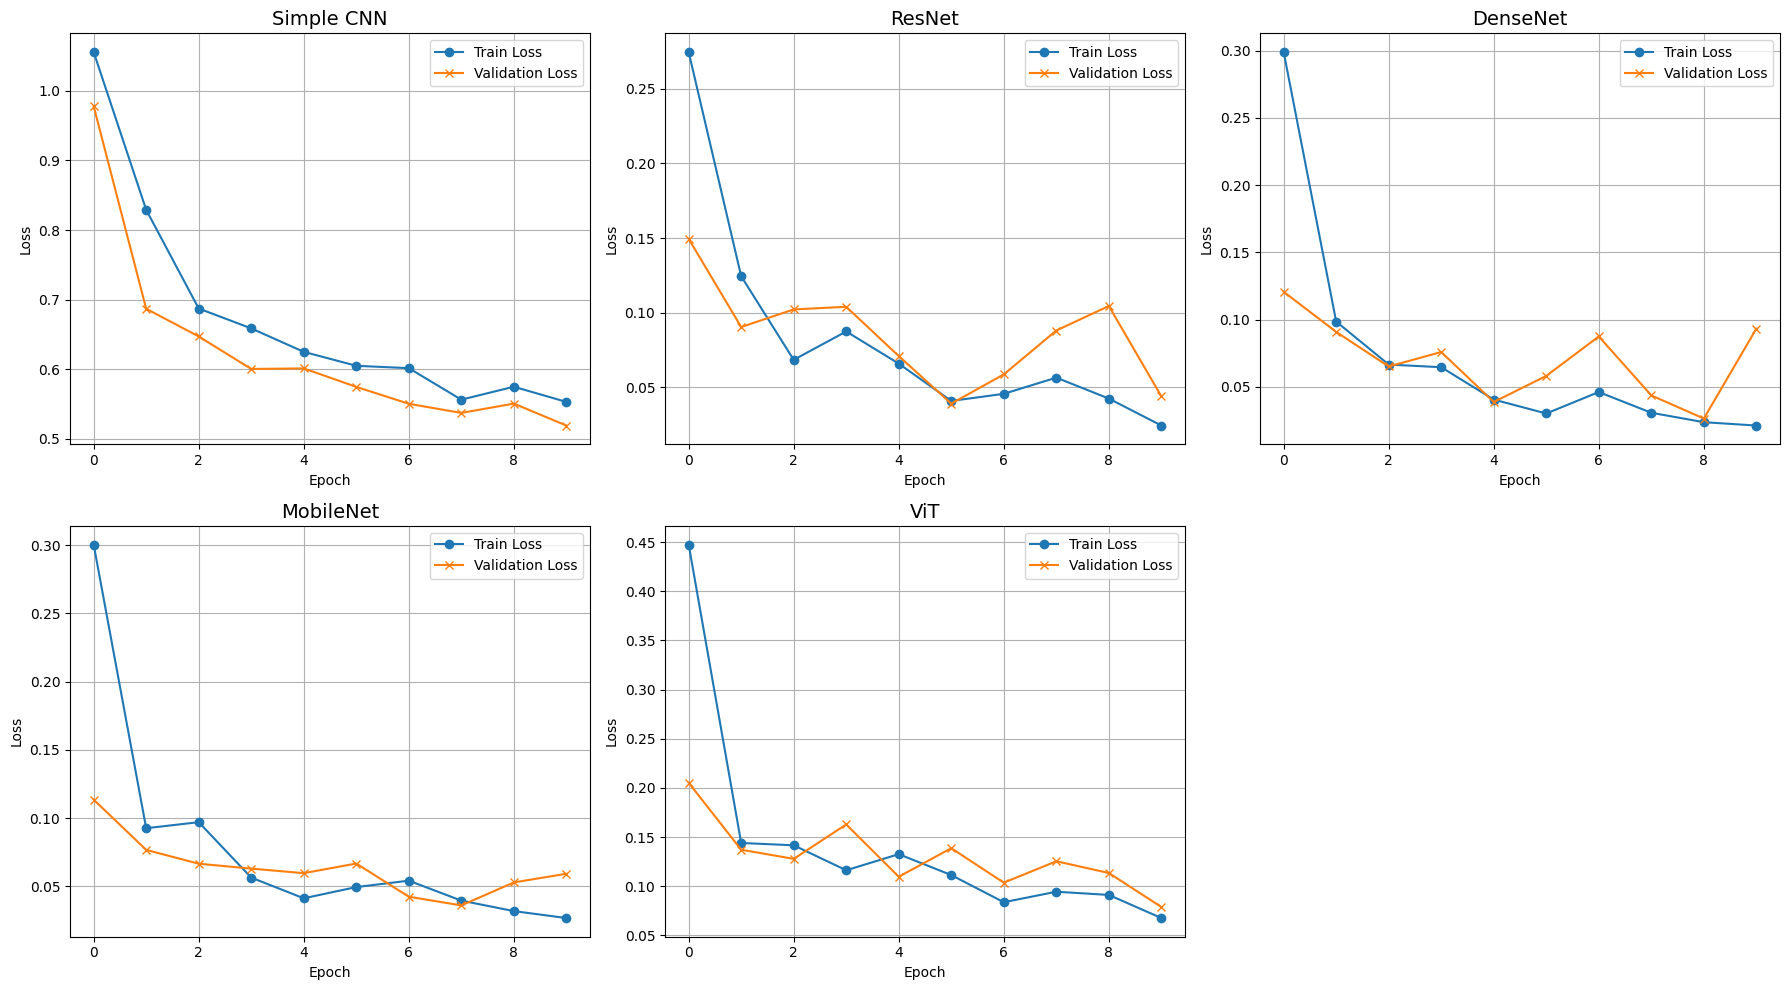

In [31]:
learning_curves = {
    "Simple CNN": (cnn_train, cnn_val),
    "ResNet": (resnet_train, resnet_val),
    "DenseNet": (densenet_train, densenet_val),
    "MobileNet": (mobilenet_train, mobilenet_val),
    "ViT": (vit_train, vit_val),
}

plot(learning_curves)

Compare Test Results Numerically

In [32]:
def evaluate_models(models_dict, data_loader, device):

    results = {
        "Model": [],
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1": []
    }

    for name, model in models_dict.items():
        model.eval()
        all_preds = []
        all_labels = []

        with torch.no_grad():
            for images, labels in data_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        acc = accuracy_score(all_labels, all_preds)
        prec = precision_score(all_labels, all_preds, average="macro")
        rec = recall_score(all_labels, all_preds, average="macro")
        f1 = f1_score(all_labels, all_preds, average="macro")

        results["Model"].append(name)
        results["Accuracy"].append(acc)
        results["Precision"].append(prec)
        results["Recall"].append(rec)
        results["F1"].append(f1)

        print(f"{name}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1={f1:.4f}")

    return pd.DataFrame(results).round(4)


In [33]:
all_models = {
    "Simple CNN": cnn,
    "ResNet": resnet,
    "DenseNet": densenet,
    "MobileNet": mobilenet,
    "ViT": vit_model
}

metrics_df = evaluate_models(all_models, test_loader, device)
metrics_df

Simple CNN: Accuracy=0.6912, Precision=0.6778, Recall=0.6769, F1=0.6746
ResNet: Accuracy=0.9632, Precision=0.9642, Recall=0.9626, F1=0.9633
DenseNet: Accuracy=0.9765, Precision=0.9772, Recall=0.9757, F1=0.9763
MobileNet: Accuracy=0.9603, Precision=0.9591, Recall=0.9597, F1=0.9593
ViT: Accuracy=0.9529, Precision=0.9519, Recall=0.9528, F1=0.9522


,Model,Accuracy,Precision,Recall,F1
0,Simple CNN,0.6912,0.6778,0.6769,0.6746
1,ResNet,0.9632,0.9642,0.9626,0.9633
2,DenseNet,0.9765,0.9772,0.9757,0.9763
3,MobileNet,0.9603,0.9591,0.9597,0.9593
4,ViT,0.9529,0.9519,0.9528,0.9522


Feature Visualization (Grad-CAM, Saliency Maps and CheferViTExplainer)

In [34]:
import types

def densenet_forward_no_inplace_for_saliency(self, x: torch.Tensor) -> torch.Tensor:
    features = self.features(x)
    # Clone 'features' to avoid the in-place operation on a view
    out = F.relu(features.clone(), inplace=False) # Changed to clone and inplace=False
    out = F.adaptive_avg_pool2d(out, (1, 1))
    out = torch.flatten(out, 1)
    out = self.classifier(out)
    return out

def plot_saliency(models_dict, image, label, device, figsize=(18,10)):
    num_models = len(models_dict)

    # Layout: first row 2, second row remaining
    if num_models <= 2:
        rows, cols = 1, num_models
    else:
        rows, cols = 2, (num_models + 1) // 2  # ceil division

    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()

    for ax, (name, model) in zip(axes, models_dict.items()):
        model.eval()
        img = image.unsqueeze(0).to(device)
        img.requires_grad = True

        original_forward = None
        if isinstance(model, models.densenet.DenseNet):
            original_forward = model.forward
            model.forward = types.MethodType(densenet_forward_no_inplace_for_saliency, model)

        try:
            output = model(img)
            loss = output[0, label]
            model.zero_grad()
            loss.backward()

            saliency = img.grad.abs().squeeze().cpu()
            saliency, _ = torch.max(saliency, dim=0)

            ax.imshow(to_pil_image(image.cpu()))
            ax.imshow(saliency, cmap='hot', alpha=0.5)
            ax.set_title(name, fontsize=12)
            ax.axis('off')
        finally:
            if original_forward:
                model.forward = original_forward

    # Hide any extra axes (if grid bigger than number of models)
    for j in range(len(models_dict), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

In [35]:
# ---------- Smooth Grad-CAM for CNN-like models ----------
import types

def densenet_forward_no_inplace(self, x: torch.Tensor) -> torch.Tensor:
    features = self.features(x)
    # Clone 'features' to avoid the in-place operation on a view
    out = F.relu(features.clone(), inplace=False) # Changed to clone and inplace=False
    out = F.adaptive_avg_pool2d(out, (1, 1))
    out = torch.flatten(out, 1)
    out = self.classifier(out)
    return out

class SmoothGradCAM:
    """Smooth Grad-CAM for CNN-like models."""
    def __init__(self, model, target_layer, n_samples=20, noise_level=0.1):
        self.model = model
        self.target_layer = target_layer
        self.n_samples = n_samples
        self.noise_level = noise_level
        self.activations = None
        self.gradients = None
        self.hooks = []

        # Hooks to save activations & gradients
        self.hooks.append(
            target_layer.register_forward_hook(lambda m, inp, out: setattr(self, "activations", out.clone()))
        )
        self.hooks.append(
            target_layer.register_full_backward_hook(lambda m, grad_in, grad_out: setattr(self, "gradients", grad_out[0].clone()))
        )

    def remove_hooks(self):
        for h in self.hooks:
            h.remove()

    def __call__(self, x, target_class):
        device = next(self.model.parameters()).device
        x = x.unsqueeze(0).to(device)
        x.requires_grad_()

        total_cam = 0

        # Store original forward method and potentially replace it for DenseNet
        original_forward = None
        if isinstance(self.model, models.densenet.DenseNet):
            original_forward = self.model.forward
            self.model.forward = types.MethodType(densenet_forward_no_inplace, self.model)

        # Temporarily set inplace=False for ReLU layers
        original_inplace_states = {}
        for module in self.model.modules():
            if isinstance(module, nn.ReLU) and module.inplace:
                original_inplace_states[module] = True
                module.inplace = False

        try:
            for _ in range(self.n_samples):
                scale = x.detach().std()
                noise = torch.randn_like(x) * self.noise_level * scale
                noisy_input = x + noise
                noisy_input.requires_grad_()
                self.model.zero_grad()

                output = self.model(noisy_input)
                score = output[0, target_class]
                score.backward(retain_graph=True)

                grads = self.gradients
                acts = self.activations
                weights = torch.mean(grads, dim=(2,3), keepdim=True)
                cam = torch.sum(weights * acts, dim=1).squeeze(0)
                total_cam += cam.detach().cpu()

        finally:
            # Restore original inplace states
            for module, was_inplace in original_inplace_states.items():
                if was_inplace:
                    module.inplace = True
            # Restore original DenseNet forward method if it was replaced
            if original_forward:
                self.model.forward = original_forward

        avg_cam = total_cam / self.n_samples
        avg_cam = avg_cam - avg_cam.min()
        avg_cam = avg_cam / (avg_cam.max() + 1e-7)
        return avg_cam


def plot_gradcam(models_dict, image, target_class, target_layer_dict=None,
                 n_samples=20, noise_level=0.1, figsize=(18,10)):

    """
    Plot Smooth Grad-CAM for multiple CNN models in a grid.
    models_dict: {"ModelName": model_instance, ...}
    target_layer_dict: optional {"ModelName": layer} for CNNs
    """
    num_models = len(models_dict)

    # Layout: first row 2, second row remaining
    if num_models <= 2:
        rows, cols = 1, num_models
    else:
        rows = 2
        cols = (num_models + 1) // 2  # ceil division for second row

    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()

    for ax, (name, model) in zip(axes, models_dict.items()):
        model.eval()
        device = next(model.parameters()).device

        # Choose target layer
        if target_layer_dict and name in target_layer_dict:
            target_layer = target_layer_dict[name]
        else:
            target_layer = list(model.modules())[-1]  # fallback

        # SmoothGrad-CAM
        gradcam = SmoothGradCAM(model, target_layer, n_samples, noise_level)
        heatmap = gradcam(image, target_class)
        gradcam.remove_hooks()

        # Resize heatmap to image size
        heatmap_resized = F.interpolate(
            heatmap.unsqueeze(0).unsqueeze(0),
            size=(image.shape[1], image.shape[2]),
            mode="bilinear",
            align_corners=False
        ).squeeze().cpu().numpy()

        img_pil = to_pil_image(image.cpu())

        # Overlay
        ax.imshow(img_pil)
        ax.imshow(heatmap_resized, cmap="jet", alpha=0.5)
        ax.set_title(name, fontsize=12)
        ax.axis("off")

    # Hide extra axes
    for j in range(len(models_dict), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

In [36]:
class CheferViTExplainer:
    def __init__(self, model):
        self.model = model
        self.model.eval()
        self.attentions = []
        self.attn_gradients = []
        self.hooks = []
        self._register_hooks()

    def _save_gradient(self, module, grad_input, grad_output):
        self.attn_gradients.append(grad_output[0])

    def _save_attention(self, module, input, output):
        self.attentions.append(output)

    def _register_hooks(self):
        print("--- Registering Hooks ---")
        if hasattr(self.model, 'vit') and hasattr(self.model.vit, 'blocks'):
            blocks = self.model.vit.blocks
        elif hasattr(self.model, 'blocks'):
            blocks = self.model.blocks
        else:
            return

        success_count = 0
        for block in blocks:
            # Hook the Dropout layer inside Attention
            if hasattr(block, 'attn') and hasattr(block.attn, 'attn_drop'):
                target = block.attn.attn_drop
                self.hooks.append(target.register_forward_hook(self._save_attention))
                self.hooks.append(target.register_backward_hook(self._save_gradient)) # Changed to regular backward hook
                success_count += 1
        print(f"--- Hooks registered on {success_count} blocks ---")

    def generate_map(self, input_tensor, target_class=None):
        self.attentions = []
        self.attn_gradients = []

        # 1. Force Gradients (Even in Eval Mode)
        torch.set_grad_enabled(True)
        for param in self.model.parameters():
            param.requires_grad = True

        # --- Temporarily force attn_drop modules to train mode to ensure hooks fire ---
        attn_drop_modules = []
        original_attn_drop_training_states = {}
        if hasattr(self.model, 'vit') and hasattr(self.model.vit, 'blocks'):
            for block in self.model.vit.blocks:
                if hasattr(block.attn, 'attn_drop'):
                    attn_drop_module = block.attn.attn_drop
                    attn_drop_modules.append(attn_drop_module)
                    original_attn_drop_training_states[attn_drop_module] = attn_drop_module.training
                    attn_drop_module.train() # Force to train mode
        # ------------------------------------------------------------------------------

        try:

            with torch.backends.cuda.sdp_kernel(enable_flash=False, enable_mem_efficient=False, enable_math=True):
                output = self.model(input_tensor)
        except (AttributeError, RuntimeError):
            # Fallback for older PyTorch or CPU
            output = self.model(input_tensor)

        # --- Restore original attn_drop training states ---
        for attn_drop_module in attn_drop_modules:
            if original_attn_drop_training_states[attn_drop_module]:
                attn_drop_module.train()
            else:
                attn_drop_module.eval()
        # ---------------------------------------------------

        # Check success immediately
        if not self.attentions:
            print("CRITICAL ERROR: Still no attention maps!")
            print("Attempting desperate fallback: Manually disabling fast_attn flags...")
            # Emergency Fix: Manually flip flags in timm models if they exist
            if hasattr(self.model, 'vit'):
                for m in self.model.vit.modules():
                    if hasattr(m, 'fused_attn'): m.fused_attn = False
            # Retry
            output = self.model(input_tensor)

        if target_class is None:
            target_class = output.argmax(dim=1).item()

        # 3. Backward Pass
        self.model.zero_grad()
        one_hot = torch.zeros_like(output)
        one_hot[0][target_class] = 1
        output.backward(gradient=one_hot, retain_graph=True)

        # 4. Generate Heatmap
        if not self.attentions:
            print("FAILED: Could not capture maps. Model is skipping the layer.")
            return np.zeros((input_tensor.shape[2], input_tensor.shape[3]))

        attentions = self.attentions
        gradients = self.attn_gradients[::-1]

        num_tokens = attentions[0].shape[-1]
        rollout = torch.eye(num_tokens).to(attentions[0].device)

        for i in range(len(attentions)):
            grad_attn = (gradients[i] * attentions[i]).clamp(min=0).mean(dim=1)
            rollout = rollout + torch.matmul(grad_attn, rollout)

        cls_relevance = rollout[0, 0, 1:]
        side_length = int(np.sqrt(cls_relevance.shape[0]))
        heatmap = cls_relevance.reshape(side_length, side_length).cpu().detach().numpy()
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min())
        heatmap = cv2.resize(heatmap, (input_tensor.shape[3], input_tensor.shape[2]))

        return heatmap

    def cleanup(self):
        for h in self.hooks: h.remove()

    @staticmethod
    def plot_chefer_result(original_image, heatmap, title="Chefer ViT Explanation"):
        if original_image.max() <= 1.0: img_255 = np.uint8(255 * original_image)
        else: img_255 = np.uint8(original_image)

        heatmap_255 = np.uint8(255 * heatmap)
        heatmap_color = cv2.cvtColor(cv2.applyColorMap(heatmap_255, cv2.COLORMAP_JET), cv2.COLOR_BGR2RGB)
        superimposed = cv2.addWeighted(img_255, 0.6, heatmap_color, 0.4, 0)

        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].imshow(img_255); axes[0].set_title("Original"); axes[0].axis('off')
        axes[1].imshow(superimposed); axes[1].set_title(title); axes[1].axis('off')
        plt.show()

Saliency Maps

In [46]:
images, labels = next(iter(test_loader))
image = images[13]
label = labels[13].item()

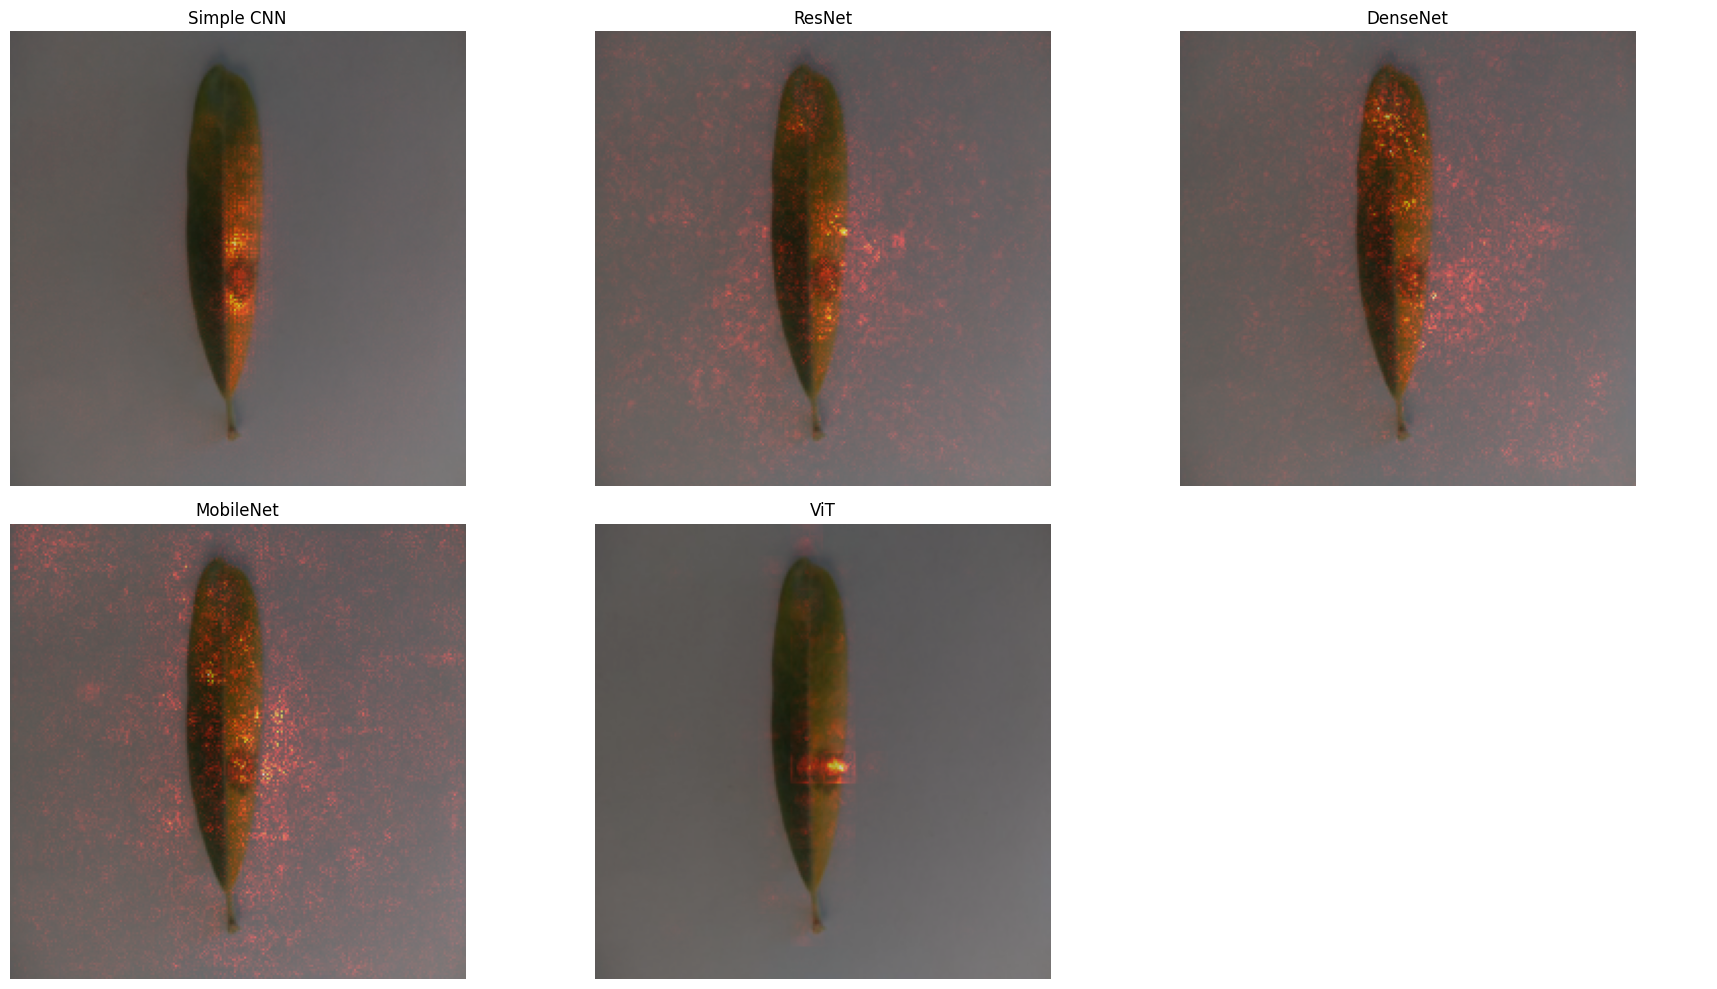

In [47]:
models_dict = {
    "Simple CNN": cnn,
    "ResNet": resnet,
    "DenseNet": densenet,
    "MobileNet": mobilenet,
    "ViT": vit_model
}

plot_saliency(models_dict, image, label, device)

Grad-CAM

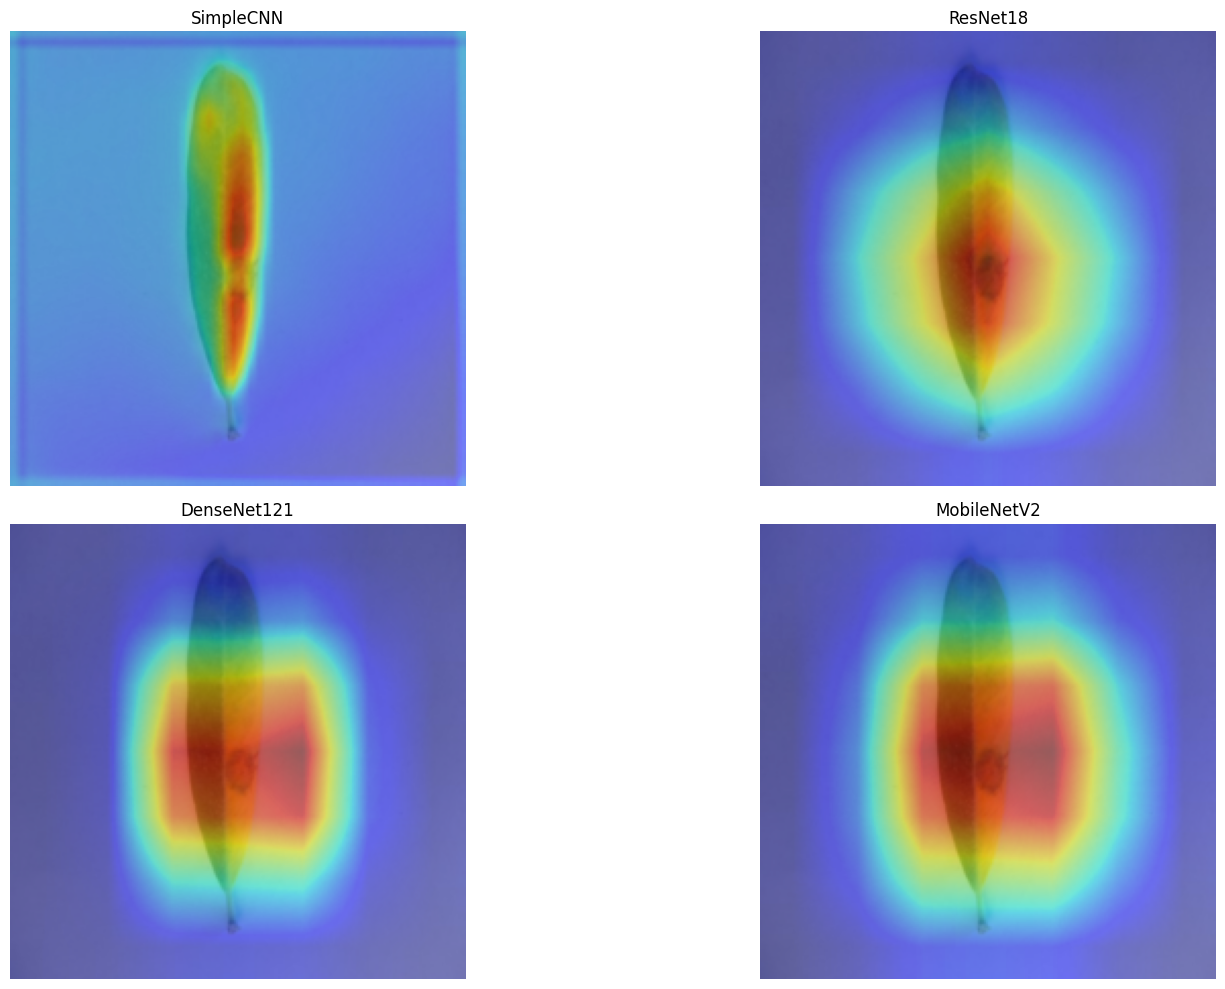

In [40]:
cnn_models_dict = {
    "SimpleCNN": cnn,
    "ResNet18": resnet,
    "DenseNet121": densenet,
    "MobileNetV2": mobilenet
}

target_layer_dict = {
    "SimpleCNN": cnn.features[6],
    "ResNet18": resnet.layer4[-1],
    "DenseNet121": densenet.features.norm5,
    "MobileNetV2": mobilenet.features[-1][0]
}

plot_gradcam(cnn_models_dict, image, target_class=label, target_layer_dict=target_layer_dict)

CheferViTExplainer on ViT



--- Registering Hooks ---
--- Hooks registered on 12 blocks ---
Generating map for Class 2...


/usr/lib/python3.12/contextlib.py:105: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
/usr/local/lib/python3.12/dist-packages/torch/nn/modules/module.py:1866: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


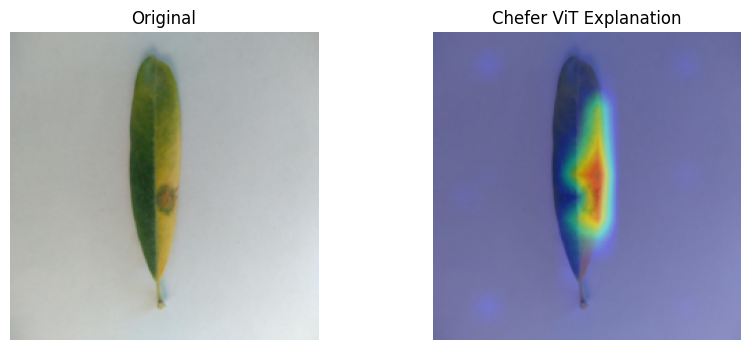

In [41]:
# STEP 0: CLEANUP ZOMBIE HOOKS
for name, module in vit_model.named_modules():
    if hasattr(module, "_forward_hooks"): module._forward_hooks.clear()
    if hasattr(module, "_backward_hooks"): module._backward_hooks.clear()

idx = 13
img = images[idx]
target_label = labels[idx].item()

explainer = CheferViTExplainer(vit_model)
input_tensor = img.unsqueeze(0).to(device)

print(f"Generating map for Class {target_label}...")
heatmap = explainer.generate_map(input_tensor, target_class=target_label)

explainer.cleanup()

img_for_plot = img.permute(1, 2, 0).cpu().numpy()
CheferViTExplainer.plot_chefer_result(img_for_plot, heatmap)